In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Dropout,Dense,SimpleRNN,Embedding
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# LOAD

In [5]:

df = pd.read_csv(r'c:\Users\HP\Downloads\archive (6)\spam.csv', encoding='latin-1')

In [6]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [7]:
df = df.iloc[:, :2]

df.columns = ["label", "message"]

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
df.shape

(5572, 2)

In [9]:
df.isnull().sum()

label      0
message    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(403)

In [11]:
df=df.drop_duplicates(subset=['label','message'])
df.duplicated().sum()

np.int64(0)

In [12]:
df['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

In [13]:
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df = df.dropna()

df["label"] = df["label"].astype(int)

print(df.head())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


In [15]:
import re

# Clean Text

In [14]:
def clean_text(text):
    text=text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [16]:
df["clean_message"] = df["message"].apply(clean_text)

df.head()

,label,message,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,0,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


# X and Y

In [17]:
X = df["clean_message"]

y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)

print("Testing:", X_test.shape)

Training: (4135,)
Testing: (1034,)


# Tokenize

In [19]:
tokenizer=Tokenizer(num_words=10000,oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

In [20]:
X_train_seq=tokenizer.texts_to_sequences(X_train)
X_test_seq=tokenizer.texts_to_sequences(X_test)

In [27]:
print("X_train:",X_train[1])
print("X_train_seq:",X_train_seq[1])


X_train: ok lar joking wif u oni
X_train_seq: [538, 27, 215, 674, 309]


In [21]:
word_index=tokenizer.word_index
print("Vocabulary Size:", len(word_index))

Vocabulary Size: 6766


In [22]:
max_length=50
X_train_pad=pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [29]:
print(X_train_pad[1])

[538  27 215 674 309   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [24]:
X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [30]:

print("Training Shape:", X_train_pad.shape)

print("Testing Shape:", X_test_pad.shape)

Training Shape: (4135, 50)
Testing Shape: (1034, 50)


# Split Sentences

In [31]:
sentence=[
    message.split()
    for message in X_train
]

In [32]:
print(sentence)

[['cool', 'so', 'how', 'come', 'you', 'havent', 'been', 'wined', 'and', 'dined', 'before'], ['huh', 'so', 'late', 'fr', 'dinner'], ['my', 'ex', 'wife', 'was', 'not', 'able', 'to', 'have', 'kids', 'do', 'you', 'want', 'kids', 'one', 'day'], ['hope', 'ur', 'head', 'doesn', 't', 'hurt', 'much', 'am', 'ploughing', 'my', 'way', 'through', 'a', 'pile', 'of', 'ironing', 'staying', 'in', 'with', 'a', 'chinky', 'tonight', 'come', 'round', 'if', 'you', 'like'], ['ryder', 'unsold', 'now', 'gibbs'], ['guess', 'which', 'pub', 'im', 'in', 'im', 'as', 'happy', 'as', 'a', 'pig', 'in', 'clover', 'or', 'whatever', 'the', 'saying', 'is'], ['ok', 'set', 'let', 'u', 'noe', 'e', 'details', 'later'], ['anything', 'lar', 'then', 'not', 'going', 'home', 'dinner'], ['bring', 'tat', 'cd', 'don', 'forget'], ['stop', 'calling', 'everyone', 'saying', 'i', 'might', 'have', 'cancer', 'my', 'throat', 'hurts', 'to', 'talk', 'i', 'can', 't', 'be', 'answering', 'everyones', 'calls', 'if', 'i', 'get', 'one', 'more', 'call

# Word2vec Model

In [33]:
from gensim.models import Word2Vec

In [36]:
model=Word2Vec(
    sentence,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=50,
    seed=42
)

In [35]:
print("Vocabulary:", len(model.wv))

print(
    model.wv.most_similar("free", topn=10)
)

Vocabulary: 6765
[('colour', 0.914444088935852), ('nokia', 0.9077218174934387), ('messages', 0.9064576029777527), ('camcorder', 0.8868309855461121), ('latest', 0.8830580115318298), ('update', 0.8811856508255005), ('tone', 0.881072461605072), ('camera', 0.8730742335319519), ('unlimited', 0.8715994358062744), ('services', 0.8693382740020752)]


# Create Word2Vec embedding matrix

In [44]:
VOCAB_SIZE = (len(word_index)+1)

EMBEDDING_DIM = 100

embedding_matrix = np.zeros(
    (VOCAB_SIZE, EMBEDDING_DIM)
)

for word, index in word_index.items():

    if index >= VOCAB_SIZE:
        continue

    if word in model.wv:

        embedding_matrix[index] = model.wv[word]

print("Embedding Matrix Shape:", embedding_matrix.shape)

Embedding Matrix Shape: (6767, 100)


# RNN MOdel

In [45]:
from tensorflow.keras.models import Sequential
rnn_model=Sequential([
    Embedding(input_dim=VOCAB_SIZE,output_dim=EMBEDDING_DIM,weights=[embedding_matrix],input_length=max_length,trainable=True),
    SimpleRNN(64,activation='tanh'),
    Dropout(0.3),
    Dense(32,activation='relu'),
    Dropout(0.3),
    Dense(1,activation='sigmoid')
])

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


# Complie

In [48]:
rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │       676,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,700 (2.58 MB)

 Trainable params: 676,700 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

# Early Stop

In [49]:
from tensorflow.keras.callbacks import EarlyStopping

In [50]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# FIT

In [52]:
history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9090 - loss: 0.2456 - val_accuracy: 0.9637 - val_loss: 0.0982
Epoch 2/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9704 - loss: 0.1317 - val_accuracy: 0.9698 - val_loss: 0.0949
Epoch 3/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9444 - loss: 0.2075 - val_accuracy: 0.9734 - val_loss: 0.1237
Epoch 4/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9568 - loss: 0.1923 - val_accuracy: 0.9674 - val_loss: 0.1424
Epoch 5/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9571 - loss: 0.1907 - val_accuracy: 0.9722 - val_loss: 0.1256
Epoch 6/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9577 - loss: 0.1866 - val_accuracy: 0.9686 - val_loss: 0.1401


# Model evaluate

In [54]:
loss,accuracy_score=rnn_model.evaluate(X_test_pad,y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy_score)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9749 - loss: 0.1997
Test Loss: 0.19974631071090698
Test Accuracy: 0.9748549461364746


In [55]:
y_pred_prob = rnn_model.predict(X_test_pad)

y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99       903
        Spam       0.89      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034



In [58]:
from sklearn.metrics import accuracy_score,precision_score,recall_score

In [60]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))


Accuracy: 0.9748549323017408
Precision: 0.8888888888888888
Recall: 0.916030534351145


# Accuracy Score

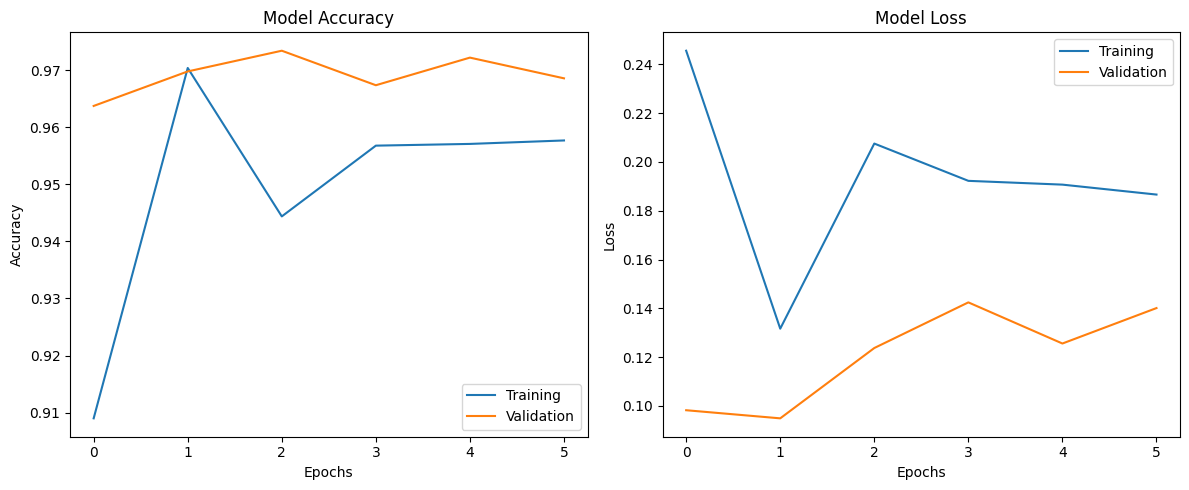

In [61]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history["accuracy"], label="Training")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1,2,2)

plt.plot(history.history["loss"], label="Training")

plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [62]:
def predict(message):
    cleaned=clean_text(message)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )
    
    prediction = rnn_model.predict(padded, verbose=0)[0][0]
    if prediction >= 0.5:
        print("SPAM MESSAGE")

    else:

        print("LEGITIMATE MESSAGE")

        print("Spam Probability:", round(float(prediction), 4) * 100, "%")

In [64]:
predict(
    "Congratulations! You have won a free lottery prize. Claim now!"
)

SPAM MESSAGE


In [65]:
predict(
    "URGENT! You have won 5000 dollars. Call this number now!"
)

LEGITIMATE MESSAGE
Spam Probability: 32.53 %


In [67]:
import pickle
rnn_model.save("spam_Rnn_word2vec.keras")

with open("spam_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("All models saved successfully!")

All models saved successfully!
